# Real-Time Speech Denoising with a Lightweight GRU

The goal of this project is to remove background noise from speech with a model small and fast enough to run in real time on an embedded device. A GRU network of under 1M parameters predicts a time-frequency mask from the noisy spectrogram. On the VoiceBank-DEMAND test set, it improves the SNR by 9 dB and PESQ from 1.97 to 2.71, and once converted to TensorFlow Lite in int8 it weighs 1.81 MB and runs about 90 times faster than real time on a single CPU thread.

## 1. Setup

Everything runs on Google Colab (free tier), with the dataset cached from Hugging Face and the trained model and results saved to my Google Drive. With TRAIN = False, the notebook reloads the model I already trained instead of retraining it, so it can be re-run in about half an hour.

In [1]:
!pip install -q -U datasets soundfile pesq pystoi

import os, io, time
import numpy as np
import pandas as pd
import soundfile as sf
import librosa, librosa.display
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tqdm.auto import tqdm
from IPython.display import Audio as Play, display
from pesq import pesq
from pystoi import stoi

from google.colab import drive
drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/speech-denoiser"
MODEL_DIR = f"{BASE}/models"
OUT = f"{BASE}/examples"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

TRAIN = False  # True to retrain from scratch (about 2.5 h), False to load the saved model

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 16.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 25.0.1 which is incompatible.
Mounted at /content/drive


## 2. Data: VoiceBank-DEMAND (16 kHz)

I used VoiceBank-DEMAND, a standard benchmark for speech enhancement: the same sentence recorded clean and mixed with real-world noise (café, street, office...). That gives 11,572 training pairs (9.4 h of audio) and 824 test pairs. I kept the last 500 training clips, from speakers the model never sees, as a validation set. The audio is at 16 kHz, which is enough for speech (almost all the useful information is below 8 kHz) and three times cheaper to process than 48 kHz.

In [2]:
from datasets import load_dataset, Audio
ds = load_dataset("JacobLinCool/VoiceBank-DEMAND-16k", cache_dir="/content/hf_cache")
ds = ds.cast_column("clean", Audio(decode=False)).cast_column("noisy", Audio(decode=False))
print(ds)

def read_audio(a):
    src = io.BytesIO(a["bytes"]) if a.get("bytes") else a["path"]
    return sf.read(src)

def load_pair(ex):
    noisy, sr = read_audio(ex["noisy"])
    clean, _ = read_audio(ex["clean"])
    return noisy, clean, sr

README.md:   0%|          | 0.00/652 [00:00<?, ?B/s]

data/train-00000-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  444MB            

data/train-00000-of-00005.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00005.parquet: reconstructing file:   0%|          |  0.00B /  416MB            

data/train-00001-of-00005.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  132MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11572 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/824 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'clean', 'noisy'],
        num_rows: 11572
    })
    test: Dataset({
        features: ['id', 'clean', 'noisy'],
        num_rows: 824
    })
})


Sample rate: 16000 Hz | duration: 2.28 s
Noisy:


Clean:


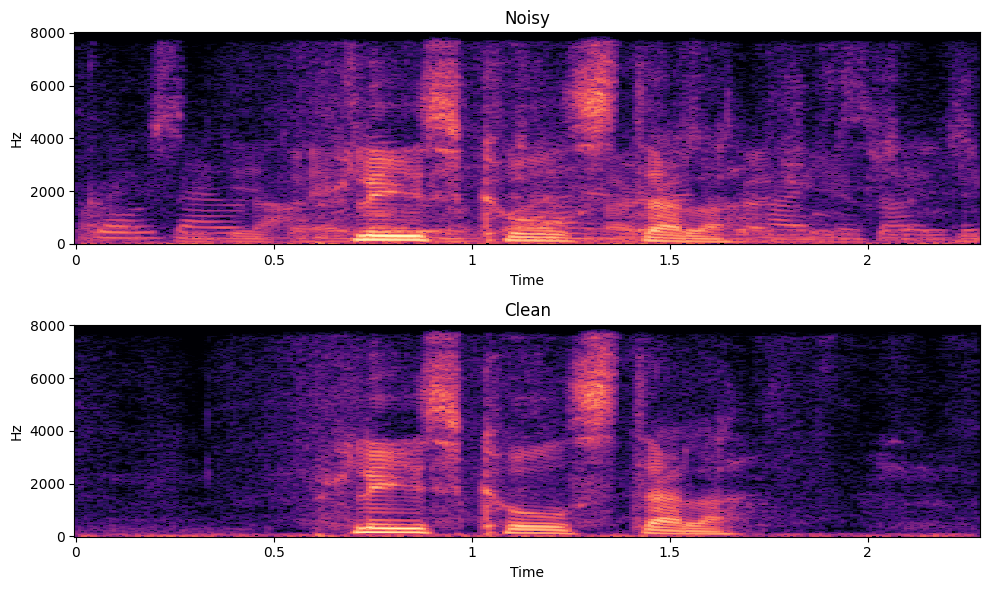

In [3]:
x_n, x_c, sr = load_pair(ds["train"][0])
print(f"Sample rate: {sr} Hz | duration: {len(x_c)/sr:.2f} s")
print("Noisy:"); display(Play(x_n, rate=sr))
print("Clean:"); display(Play(x_c, rate=sr))

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, x, title in zip(axes, [x_n, x_c], ["Noisy", "Clean"]):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(x, n_fft=512, hop_length=128)), ref=np.max)
    librosa.display.specshow(S, sr=sr, hop_length=128, x_axis="time", y_axis="hz", ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.show()

In [4]:
SR = 16000

def to_int16(x):
    return (np.clip(x, -1, 1) * 32767).astype(np.int16)  # half the memory of float32

def load_split(split):
    N, C = [], []
    for ex in tqdm(ds[split], desc=split):
        n, c, _ = load_pair(ex)
        L = min(len(n), len(c))
        N.append(to_int16(n[:L])); C.append(to_int16(c[:L]))
    return N, C

train_noisy, train_clean = load_split("train")
test_noisy, test_clean = load_split("test")
hours = sum(len(x) for x in train_noisy) / SR / 3600
print(f"{len(train_noisy)} training clips, {hours:.1f} h of audio")

# Last 500 training clips (unseen speakers) held out for validation
val_noisy, val_clean = train_noisy[-500:], train_clean[-500:]
train_noisy, train_clean = train_noisy[:-500], train_clean[:-500]
print(f"Train: {len(train_noisy)} | Validation: {len(val_noisy)} | Test: {len(test_noisy)}")

train:   0%|          | 0/11572 [00:00<?, ?it/s]

test:   0%|          | 0/824 [00:00<?, ?it/s]

11572 training clips, 9.4 h of audio
Train: 11072 | Validation: 500 | Test: 824


## 3. STFT and the oracle mask

Instead of working on the raw waveform, I convert the audio to a spectrogram (32 ms windows, 8 ms hop, 257 frequency bins). The network doesn't generate speech: it predicts a mask between 0 and 1 for each time-frequency cell, which says how much of the noisy signal to keep. The oracle mask is the "perfect" mask, computed with access to the clean speech. It's "cheating", but it shows the best result this approach could ever reach, so I use it as an upper bound. On this first example it brings the SNR from 12.3 dB to 19.9 dB.

In [5]:
N_FFT = 512   # 32 ms window at 16 kHz
HOP = 128     # 8 ms hop
F = N_FFT // 2 + 1  # 257 frequency bins
win = tf.signal.hann_window

def stft(x):
    return tf.signal.stft(x, frame_length=N_FFT, frame_step=HOP, fft_length=N_FFT, window_fn=win)

def istft(S):
    return tf.signal.inverse_stft(S, N_FFT, HOP, N_FFT,
        window_fn=tf.signal.inverse_stft_window_fn(HOP, forward_window_fn=win))

def pad_to(y, L):
    return np.pad(y, (0, max(0, L - len(y))))[:L]

def snr_db(clean, est):
    L = min(len(clean), len(est)); clean, est = clean[:L], est[:L]
    return 10 * np.log10(np.sum(clean**2) / (np.sum((clean - est)**2) + 1e-10))

def oracle(n, c):
    Sn, Sc = stft(n), stft(c)
    mask = tf.clip_by_value(tf.abs(Sc) / (tf.abs(Sn) + 1e-8), 0.0, 1.0)
    return pad_to(istft(tf.cast(mask, tf.complex64) * Sn).numpy(), len(n)), mask

Noisy SNR: 12.3 dB -> oracle mask SNR: 19.9 dB


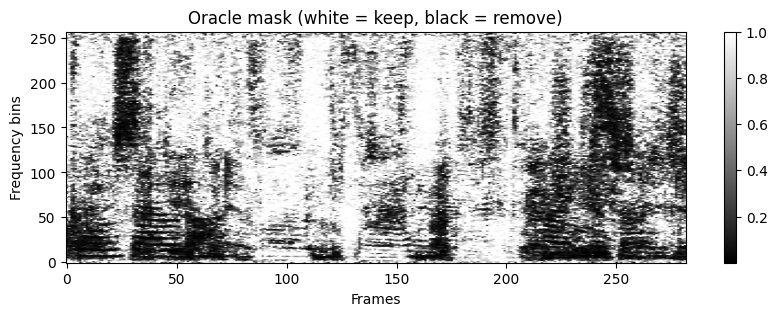

In [6]:
n = train_noisy[0].astype(np.float32) / 32767
c = train_clean[0].astype(np.float32) / 32767
o, mask = oracle(n, c)
print(f"Noisy SNR: {snr_db(c, n):.1f} dB -> oracle mask SNR: {snr_db(c, o):.1f} dB")

plt.figure(figsize=(10, 3))
plt.imshow(mask.numpy().T, origin="lower", aspect="auto", cmap="gray")
plt.title("Oracle mask (white = keep, black = remove)")
plt.xlabel("Frames"); plt.ylabel("Frequency bins"); plt.colorbar(); plt.show()

## 4. Training pipeline

At each step, the generator picks random 2-second crops from the training set, so the model sees different pieces of audio every time. The network input is the log-magnitude of the noisy spectrogram (the log compresses the huge dynamic range of audio). The target keeps both the noisy and the clean magnitudes, because the loss needs them to check the masked output. Each batch has the shape (32, 247, 257): 32 segments, 247 frames, 257 frequency bins.

In [7]:
SEG = 2 * SR
rng = np.random.default_rng(0)

def crop(n, c, start):
    n, c = n[start:start+SEG], c[start:start+SEG]
    if len(n) < SEG:
        pad = SEG - len(n); n = np.pad(n, (0, pad)); c = np.pad(c, (0, pad))
    return n.astype(np.float32) / 32767, c.astype(np.float32) / 32767

def gen():
    while True:
        i = rng.integers(len(train_noisy))
        n, c = train_noisy[i], train_clean[i]
        yield crop(n, c, rng.integers(0, max(1, len(n) - SEG + 1)))

def to_features(n, c):
    mag_n, mag_c = tf.abs(stft(n)), tf.abs(stft(c))
    x = tf.math.log(mag_n + 1e-6)          # network input: noisy log-magnitude
    y = tf.stack([mag_n, mag_c], axis=-1)  # loss target: noisy + clean magnitudes
    return x, y

spec = tf.TensorSpec([SEG], tf.float32)
train_ds = (tf.data.Dataset.from_generator(gen, output_signature=(spec, spec))
            .map(to_features, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(32).prefetch(tf.data.AUTOTUNE))

vn, vc = zip(*[crop(n, c, 0) for n, c in zip(val_noisy, val_clean)])
val_ds = tf.data.Dataset.from_tensor_slices((np.stack(vn), np.stack(vc))).map(to_features).batch(32)

xb, yb = next(iter(train_ds))
print("Input:", xb.shape, "| Target:", yb.shape)

Input: (32, 247, 257) | Target: (32, 247, 257, 2)


## 5. Model

The model is small on purpose (about 920k parameters): a normalization layer, a dense layer, two GRU layers of 256 units and a final dense layer with a sigmoid to produce the mask. I chose GRUs because they read the frames in order and keep a memory of the past, without ever needing future frames. That makes the model causal, so it can process audio as it arrives, which is what you need for real-time use on a small device.

In [8]:
def build_model(T=None, batch_size=None, streaming=False):
    inp = keras.Input(shape=(T, F), batch_size=batch_size, name="log_mag")
    x = layers.Normalization(axis=-1)(inp)
    x = layers.Dense(256, activation="relu")(x)
    gru_args = dict(use_cudnn=False, unroll=True) if streaming else {}
    x = layers.GRU(256, return_sequences=True, **gru_args)(x)
    x = layers.GRU(256, return_sequences=True, **gru_args)(x)
    out = layers.Dense(F, activation="sigmoid", name="mask")(x)
    return keras.Model(inp, out, name="gru_denoiser")

def mag_loss(y, mask):
    mag_n, mag_c = y[..., 0], y[..., 1]
    est = mask * mag_n
    # Power-law compression (0.3) gives more weight to quiet sounds
    return tf.reduce_mean(tf.square(tf.pow(est + 1e-8, 0.3) - tf.pow(mag_c + 1e-8, 0.3)))

## 6. Training

The loss compares the masked noisy magnitude with the clean magnitude, after a 0.3 power compression that gives more weight to quiet sounds, a bit like the ear does. I trained with Adam (learning rate 1e-3, gradient clipping), halving the learning rate when the validation loss stopped improving, with early stopping. The best model came at epoch 17 (validation loss 0.0095). After that the validation loss stayed flat while the training loss kept going down, a first sign of overfitting, so the run was effectively finished when my Colab session cut off at epoch 21.

In [9]:
MODEL_PATH = f"{MODEL_DIR}/gru_denoiser_best.keras"

if TRAIN:
    model = build_model()
    norm = [l for l in model.layers if isinstance(l, layers.Normalization)][0]
    norm.adapt(train_ds.map(lambda x, y: x).take(50))  # per-frequency mean / variance
    model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=mag_loss)
    callbacks = [
        keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    ]
    history = model.fit(train_ds, steps_per_epoch=300, epochs=30,
                        validation_data=val_ds, callbacks=callbacks)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="validation")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()
else:
    model = keras.models.load_model(MODEL_PATH, compile=False)

model.summary()

Model: "gru_denoiser"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ log_mag (InputLayer)            │ (None, None, 257)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, None, 257)      │           515 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 256)      │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, None, 256)      │       394,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, None, 256)      │       394,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mask (Dense)                    │ (None, None, 257)      │        66,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 922,116 (3.52 MB)

 Trainable params: 921,601 (3.52 MB)

 Non-trainable params: 515 (2.02 KB)

## 7. Denoising examples

This is the noisiest clip of the test set (clip 588): the noise is louder than the voice (-3.1 dB), and the model brings it up to 15.6 dB. Listening to it, the background noise is clearly gone, especially in the pauses, and the voice between 2.8 s and 3.7 s stays close to the clean version (the stacked harmonics and the high "s" sounds are still there).

What's left: you can still hear a click that isn't in the clean recording. It shows up as the thin vertical line at about 1.15 s, also visible around 2.6 s. These are short impulsive noises that cover all frequencies at once, and the model lets them through as if they were speech. The model also removes a bit too much in places: the quiet words around 0.4 to 0.7 s, buried under the noise, come out weaker than in the clean version, and the highest frequencies (4 to 6 kHz) between 3.2 and 3.7 s are attenuated.

Noisiest test clips: [(588, -3.1), (680, -1.3), (488, -0.7), (75, -0.7), (432, -0.7)]
Clip 588: noisy -3.1 dB -> denoised 14.5 dB
Noisy:


Denoised:


Removed by the model:


Clean reference:


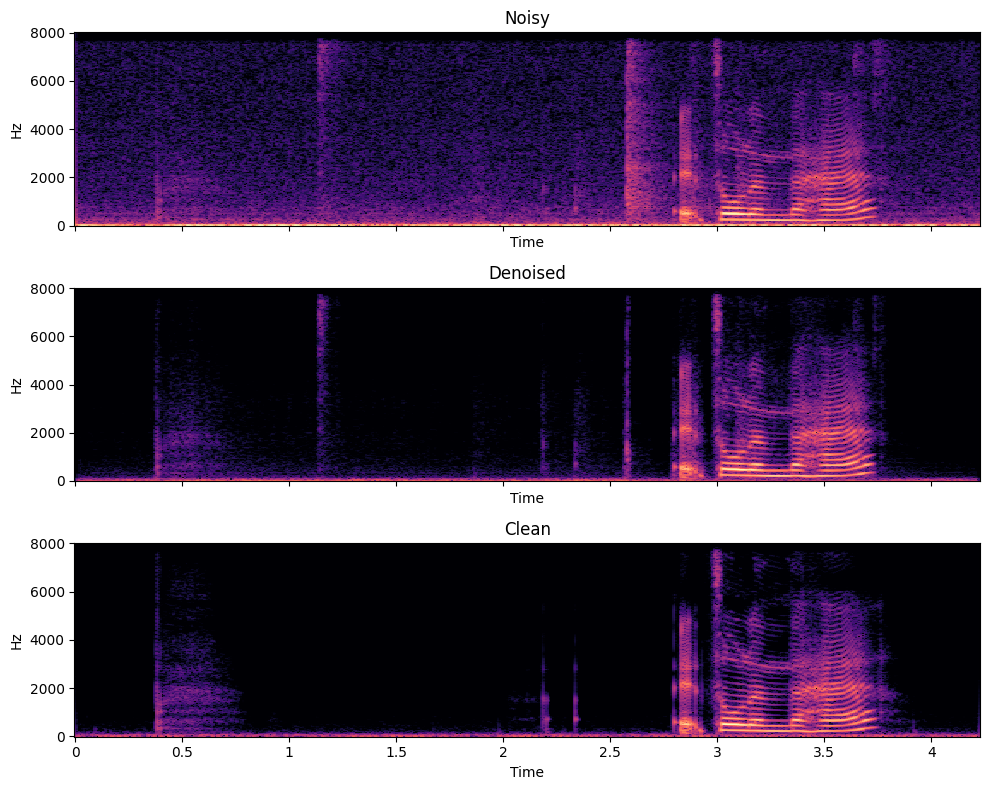

In [10]:
def enhance(x):
    S = stft(x.astype(np.float32))
    m = model(tf.math.log(tf.abs(S) + 1e-6)[None])[0]
    return pad_to(istft(tf.cast(m, tf.complex64) * S).numpy(), len(x))

def get_test(i):
    return test_noisy[i].astype(np.float32) / 32767, test_clean[i].astype(np.float32) / 32767

snrs = [snr_db(*get_test(i)[::-1]) for i in range(len(test_noisy))]
worst = np.argsort(snrs)[:5]
print("Noisiest test clips:", [(int(i), round(float(snrs[i]), 1)) for i in worst])

i = int(worst[0])
n, c = get_test(i)
e = enhance(n)
print(f"Clip {i}: noisy {snr_db(c, n):.1f} dB -> denoised {snr_db(c, e):.1f} dB")
print("Noisy:"); display(Play(n, rate=SR, normalize=False))
print("Denoised:"); display(Play(e, rate=SR, normalize=False))
print("Removed by the model:"); display(Play(n - e, rate=SR, normalize=False))
print("Clean reference:"); display(Play(c, rate=SR, normalize=False))

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, x, title in zip(axes, [n, e, c], ["Noisy", "Denoised", "Clean"]):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(x, n_fft=512, hop_length=128)), ref=np.max)
    librosa.display.specshow(S, sr=SR, hop_length=128, x_axis="time", y_axis="hz", ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.show()

In [11]:
fig.savefig(f"{OUT}/spectrogrammes_clip{i}.png", dpi=150, bbox_inches="tight")
for k in [i, 680, 0]:
    n_k, c_k = get_test(k)
    sf.write(f"{OUT}/clip{k}_1_bruite.wav", n_k, SR)
    sf.write(f"{OUT}/clip{k}_2_debruite.wav", enhance(n_k), SR)
    sf.write(f"{OUT}/clip{k}_3_propre.wav", c_k, SR)
print(sorted(os.listdir(OUT)))

['clip0_1_bruite.wav', 'clip0_2_debruite.wav', 'clip0_3_propre.wav', 'clip588_1_bruite.wav', 'clip588_2_debruite.wav', 'clip588_3_propre.wav', 'clip680_1_bruite.wav', 'clip680_2_debruite.wav', 'clip680_3_propre.wav', 'spectrogrammes_clip588.png']


## 8. Evaluation on the test set (SNR, PESQ, STOI)

Averaged over the 824 test clips, the model improves the SNR by about 9 dB (8.45 → 17.43), PESQ from 1.97 to 2.71 and STOI from 0.922 to 0.940. The "Noisy" row matches the reference values usually reported for this dataset (PESQ 1.97, STOI 0.92), which is a good sanity check that the evaluation is set up correctly.

Compared with the oracle mask, the model gets about 80% of the possible SNR gain, but only about 39% of the PESQ gain. So it removes most of the noise energy, but the perceived quality is where there's still the most room to improve, which matches what I hear: the quiet parts of the speech get damaged a bit, and some short clicks stay. STOI barely moves, which is expected since the noisy speech was already 92% intelligible.

In [12]:
rows = []
for i in tqdm(range(len(test_noisy))):
    n, c = get_test(i)
    versions = [("Noisy", n), ("Model", enhance(n)), ("Oracle", oracle(n, c)[0])]
    for name, x in versions:
        try:
            p = pesq(SR, c, x, "wb")
        except Exception:
            p = np.nan
        rows.append({"clip": i, "version": name, "SNR": snr_db(c, x),
                     "PESQ": p, "STOI": stoi(c, x, SR, extended=False)})

df = pd.DataFrame(rows)
summary = df.groupby("version")[["SNR", "PESQ", "STOI"]].mean().round(3).loc[["Noisy", "Model", "Oracle"]]
print(summary)
df.to_csv(f"{BASE}/results_test.csv", index=False)

  0%|          | 0/824 [00:00<?, ?it/s]

               SNR   PESQ   STOI
version                         
Noisy     8.450000  1.972  0.922
Model    17.431999  2.714  0.940
Oracle   19.763000  3.885  0.987


## 9. Deployment: TensorFlow Lite

To run on a small device, the model has to be converted to TensorFlow Lite. The model I trained on GPU used cuDNN GRU kernels, which TFLite can't convert, so I rebuilt the same network with standard GRU cells, a fixed input size (blocks of 125 frames, about 1 s) and an unrolled time loop, then copied the trained weights into it. Before converting, I compared both versions on the same input. The first time, the max difference was 0.95: the normalization layer had kept its default values instead of the trained ones. After forcing it to recompute them, the difference dropped to about 3e-7, which is just float32 rounding. The final int8 model weighs 1.81 MB, against 4.52 MB in float32.

In [13]:
T = 125  # frames per block, about 1.02 s of audio

fixed = build_model(T=T, batch_size=1, streaming=True)
fixed.set_weights(model.get_weights())
[l for l in fixed.layers if isinstance(l, layers.Normalization)][0].finalize_state()

xt = np.random.randn(1, T, F).astype(np.float32)
print("Max difference with the original model:", float(np.abs(fixed(xt).numpy() - model(xt).numpy()).max()))

EXPORT = "/content/denoiser_savedmodel"
fixed.export(EXPORT)

def convert(quantize, select_ops=False):
    conv = tf.lite.TFLiteConverter.from_saved_model(EXPORT)
    if quantize:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]  # int8 weights
    if select_ops:
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
        conv._experimental_lower_tensor_list_ops = False
    return conv.convert()

def safe_convert(quantize):
    try:
        return convert(quantize)
    except Exception as err:
        print("Standard conversion failed:", str(err)[:300])
        return convert(quantize, select_ops=True)

tfl_f32, tfl_int8 = safe_convert(False), safe_convert(True)
for name, b in [("float32", tfl_f32), ("int8", tfl_int8)]:
    open(f"{MODEL_DIR}/denoiser_{name}.tflite", "wb").write(b)
    print(f"TFLite {name}: {len(b)/1e6:.2f} MB")

Max difference with the original model: 2.980232238769531e-07
Saved artifact at '/content/denoiser_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 125, 257), dtype=tf.float32, name='log_mag')
Output Type:
  TensorSpec(shape=(None, 125, 257), dtype=tf.float32, name=None)
Captures:
  137990720681936: TensorSpec(shape=(1, 1, 257), dtype=tf.float32, name=None)
  137996489896208: TensorSpec(shape=(1, 1, 257), dtype=tf.float32, name=None)
  137990720670032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137990720679824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137990720900752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137990720680208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137990720898256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137990720907280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137990720900944: TensorSpec(shape=(), dtype=tf.resource, name=Non

## 10. Latency

RTF (real-time factor) is the processing time divided by the duration of the audio: below 1, the model is faster than real time. On one CPU thread, the int8 model processes a 1-second block in 11.6 ms (RTF 0.011), so roughly 90 times faster than real time, and 0.09 ms per frame, far below the 8 ms between two frames. These timings come from Colab's CPU and vary a bit between runs. A real embedded processor would be slower, but the margin is large. The Keras timing probably ran on GPU, so it isn't directly comparable.

In [14]:
x_blk = np.random.randn(1, T, F).astype(np.float32)
block_dur = ((T - 1) * HOP + N_FFT) / SR  # audio duration covered by one block

def bench_tflite(b, runs=50):
    it = tf.lite.Interpreter(model_content=b, num_threads=1)
    it.allocate_tensors()
    i_in, i_out = it.get_input_details()[0]["index"], it.get_output_details()[0]["index"]
    it.set_tensor(i_in, x_blk); it.invoke()  # warm-up
    t0 = time.perf_counter()
    for _ in range(runs):
        it.set_tensor(i_in, x_blk); it.invoke()
    return (time.perf_counter() - t0) / runs

def bench_keras(runs=20):
    model(x_blk)  # warm-up
    t0 = time.perf_counter()
    for _ in range(runs):
        model(x_blk)
    return (time.perf_counter() - t0) / runs

for name, dt in [("Keras", bench_keras()), ("TFLite float32", bench_tflite(tfl_f32)),
                 ("TFLite int8", bench_tflite(tfl_int8))]:
    print(f"{name:15s} | {dt*1000:6.1f} ms per {block_dur:.2f} s block | "
          f"{dt/T*1000:.3f} ms per frame | RTF = {dt/block_dur:.3f}")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Keras           |   20.1 ms per 1.02 s block | 0.161 ms per frame | RTF = 0.020
TFLite float32  |   36.5 ms per 1.02 s block | 0.292 ms per frame | RTF = 0.036
TFLite int8     |   11.6 ms per 1.02 s block | 0.093 ms per frame | RTF = 0.011


## 11. Quality after conversion

int8 quantization costs nothing in quality: float32 and int8 give the same PESQ (2.665 and 2.664) while int8 is smaller and about 3 times faster. The small drop compared to Keras (2.777 to 2.665) doesn't come from the conversion: it comes from processing the audio in independent 1-second blocks, so the GRUs lose their memory at every block boundary. A streaming version that carries the GRU state from one block to the next should remove this gap.

In [15]:
def enhance_tflite(x, b):
    it = tf.lite.Interpreter(model_content=b); it.allocate_tensors()
    i_in, i_out = it.get_input_details()[0]["index"], it.get_output_details()[0]["index"]
    S = stft(x.astype(np.float32)); X = np.log(np.abs(S.numpy()) + 1e-6)
    nF = X.shape[0]; Xp = np.pad(X, ((0, (-nF) % T), (0, 0)))
    M = []
    for k in range(0, Xp.shape[0], T):
        it.set_tensor(i_in, Xp[None, k:k+T].astype(np.float32)); it.invoke()
        M.append(it.get_tensor(i_out)[0])
    M = np.concatenate(M)[:nF]
    return pad_to(istft(tf.cast(M, tf.complex64) * S).numpy(), len(x))

res = {"Keras": [], "TFLite float32": [], "TFLite int8": []}
for i in tqdm(range(100)):
    n, c = get_test(i)
    for name, e in [("Keras", enhance(n)), ("TFLite float32", enhance_tflite(n, tfl_f32)),
                    ("TFLite int8", enhance_tflite(n, tfl_int8))]:
        res[name].append(pesq(SR, c, e, "wb"))
for name, v in res.items():
    print(f"{name:15s} mean PESQ (100 test clips): {np.mean(v):.3f}")

  0%|          | 0/100 [00:00<?, ?it/s]

Keras           mean PESQ (100 test clips): 2.777
TFLite float32  mean PESQ (100 test clips): 2.665
TFLite int8     mean PESQ (100 test clips): 2.664


## 12. Conclusion and next steps

With under 1M parameters, the model improves the SNR by 9 dB and PESQ from 1.97 to 2.71 on the test set, and the int8 TFLite version runs much faster than real time in under 2 MB. The main limits are perceived quality (only about 39% of the oracle's PESQ gain), short clicks that the model keeps, and quiet speech that gets attenuated. Next, I would add stateful streaming inference, train with more noise types including impulsive noises, try complex masks so the model can also correct the phase, and measure latency on an actual ARM device.